<a href="https://colab.research.google.com/github/suba466/Data-analysis/blob/main/Page_View_Time_Series_Visualizer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!wget https://raw.githubusercontent.com/freeCodeCamp/boilerplate-page-view-time-series-visualizer/main/fcc-forum-pageviews.csv

--2026-11-16 16:33:32--  https://raw.githubusercontent.com/freeCodeCamp/boilerplate-page-view-time-series-visualizer/main/fcc-forum-pageviews.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 22381 (22K) [text/plain]
Saving to: ‘fcc-forum-pageviews.csv’

fcc-forum-pageviews 100%[===================>]  21.86K  --.-KB/s    in 0s      

2026-11-16 16:33:32 (94.0 MB/s) - ‘fcc-forum-pageviews.csv’ saved [22381/22381]



In [2]:
%%writefile time_series_visualizer.py
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pandas.plotting import register_matplotlib_converters
register_matplotlib_converters()

# 1. Import data & parse dates
df = pd.read_csv('fcc-forum-pageviews.csv', parse_dates=['date'], index_col='date')

# 2. Clean data (filter out top 2.5% and bottom 2.5% of page views)
df = df[
    (df['value'] >= df['value'].quantile(0.025)) &
    (df['value'] <= df['value'].quantile(0.975))
]

def draw_line_plot():
    # Make copy of dataframe
    df_line = df.copy()

    # Draw line plot
    fig, ax = plt.subplots(figsize=(15, 5))
    ax.plot(df_line.index, df_line['value'], color='red', linewidth=1)

    ax.set_title('Daily freeCodeCamp Forum Page Views 5/2016-12/2019')
    ax.set_xlabel('Date')
    ax.set_ylabel('Page Views')

    # Save image and return fig
    fig.savefig('line_plot.png')
    return fig

def draw_bar_plot():
    # Copy and prepare data for monthly bar plot
    df_bar = df.copy()
    df_bar['year'] = df_bar.index.year
    df_bar['month'] = df_bar.index.month_name()

    # Group by year and month, then average page views
    df_grouped = df_bar.groupby(['year', 'month'])['value'].mean().unstack()

    # Reorder columns chronologically by month
    months = ['January', 'February', 'March', 'April', 'May', 'June',
              'July', 'August', 'September', 'October', 'November', 'December']
    df_grouped = df_grouped.reindex(columns=months)

    # Draw bar plot
    fig = df_grouped.plot(kind='bar', figsize=(10, 8), xlabel='Years', ylabel='Average Page Views').get_figure()
    plt.legend(title='Months')

    # Save image and return fig
    fig.savefig('bar_plot.png')
    return fig

def draw_box_plot():
    # Prepare data for box plots
    df_box = df.copy()
    df_box.reset_index(inplace=True)
    df_box['year'] = [d.year for d in df_box.date]
    df_box['month'] = [d.strftime('%b') for d in df_box.date]

    # Order months starting from Jan
    month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

    # Draw box plots using Seaborn
    fig, axes = plt.subplots(1, 2, figsize=(20, 6))

    # Year-wise Box Plot (Trend)
    sns.boxplot(x='year', y='value', data=df_box, ax=axes[0])
    axes[0].set_title('Year-wise Box Plot (Trend)')
    axes[0].set_xlabel('Year')
    axes[0].set_ylabel('Page Views')

    # Month-wise Box Plot (Seasonality)
    sns.boxplot(x='month', y='value', data=df_box, order=month_order, ax=axes[1])
    axes[1].set_title('Month-wise Box Plot (Seasonality)')
    axes[1].set_xlabel('Month')
    axes[1].set_ylabel('Page Views')

    # Save image and return fig
    fig.savefig('box_plot.png')
    return fig

Writing time_series_visualizer.py


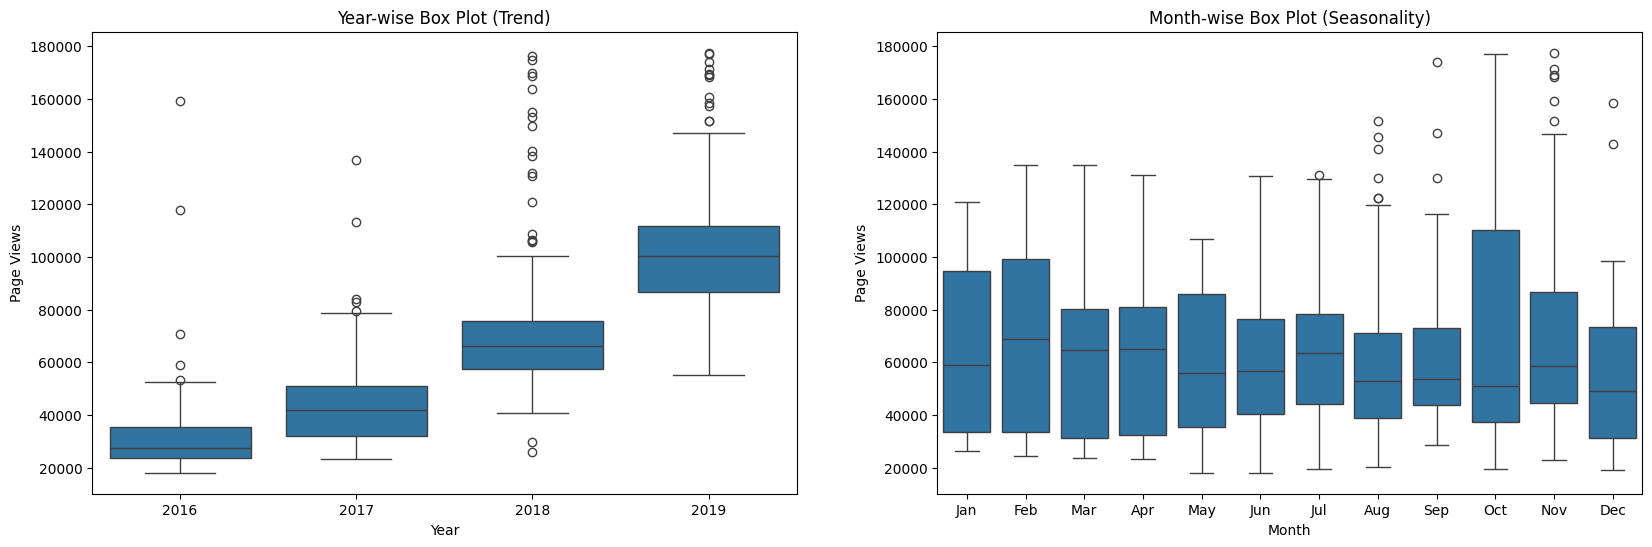

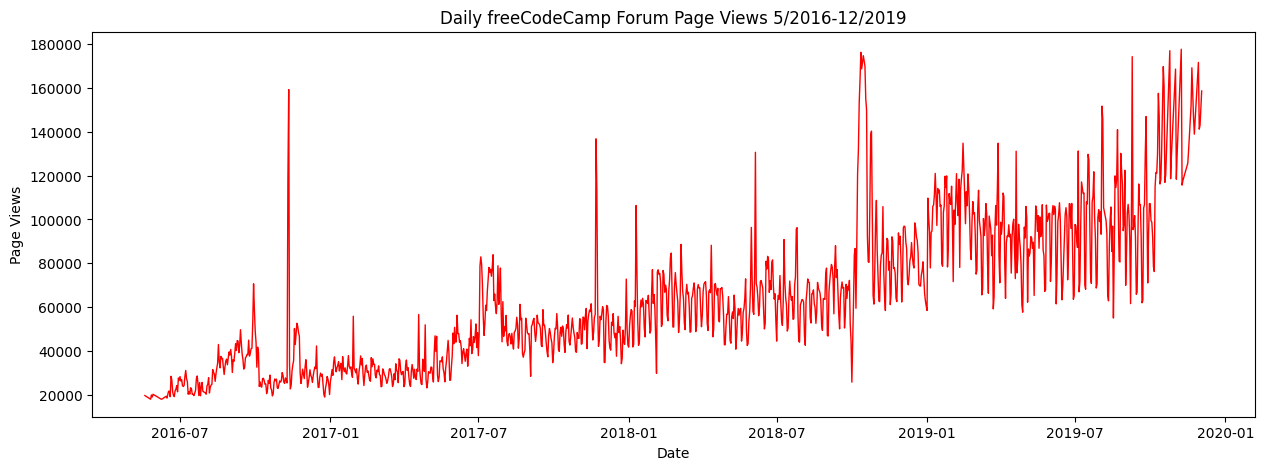

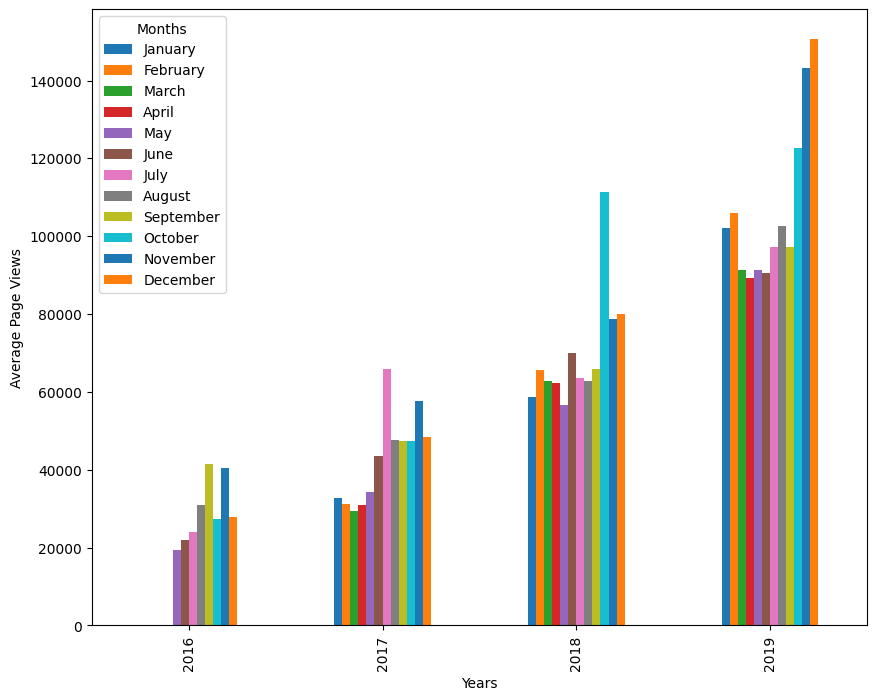

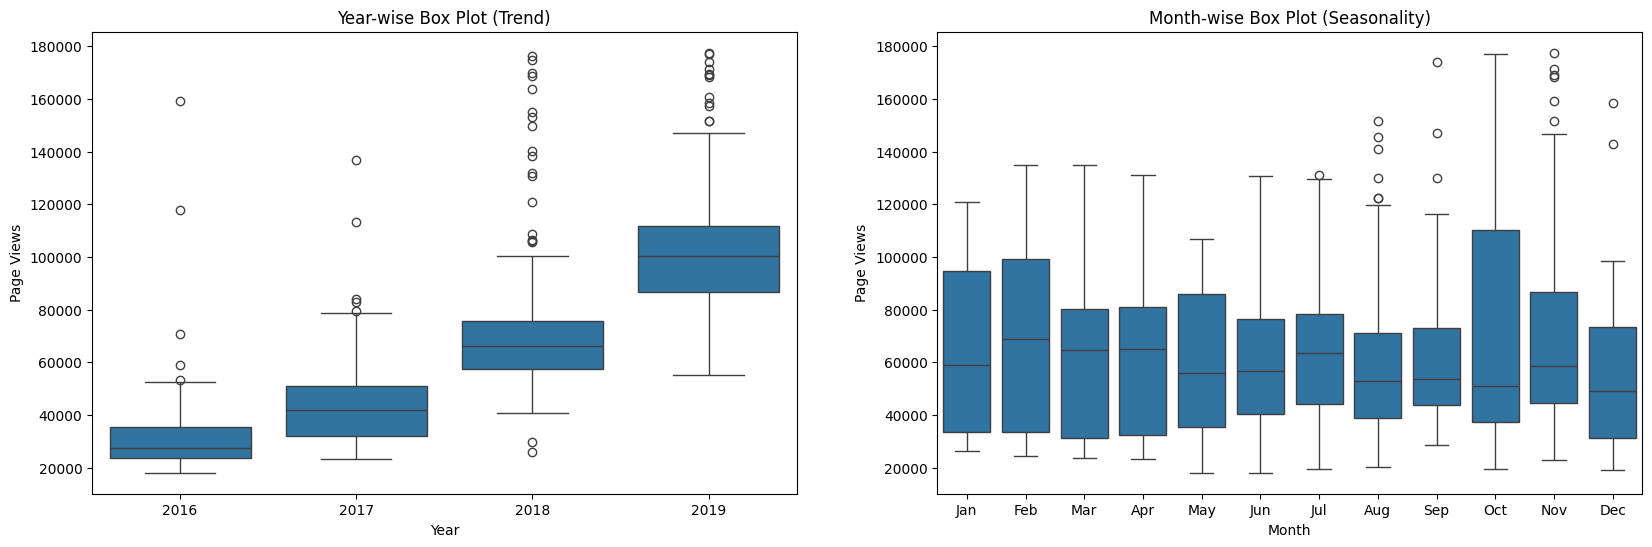

In [3]:
import time_series_visualizer

# Test line plot
time_series_visualizer.draw_line_plot()

# Test bar plot
time_series_visualizer.draw_bar_plot()

# Test box plots
time_series_visualizer.draw_box_plot()